### Familiarizing myself with hist library

In [2]:
from hist import Hist
import hist
import matplotlib.pyplot as plt
import seaborn as sns

/home/pdbforce/.local/lib/python3.8/site-packages/pandas/core/computation/expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.2' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [3]:
# fill the axes
h = Hist(
    hist.axis.Regular(
        50, -5, 5, name="S", label="s [units]", underflow=False, overflow=False
    )
)

In [4]:
import numpy as np

s_data = np.random.normal(size=50_000)
w_data = np.random.normal(size=50_000)

# normal fill
h.fill(s_data)

# Clear the data since we want to fill again with the same data
#h.reset()

# fill by names
#h.fill(W=w_data, S=s_data)

Hist(Regular(50, -5, 5, underflow=False, overflow=False, name='S', label='s [units]'), storage=Double()) # Sum: 50000.0

In [5]:
h_2 = h/h.sum()

In [6]:
h_2[10]

0.0014

In [7]:
h[8] / h_2[8]

50000.0

In [8]:
#h.show()
print(h)

                  ┌──────────────────────────────────────────────────────────┐
[  -5, -4.8) 0    │                                                          │
[-4.8, -4.6) 0    │                                                          │
[-4.6, -4.4) 0    │                                                          │
[-4.4, -4.2) 1    │                                                          │
[-4.2,   -4) 0    │                                                          │
[  -4, -3.8) 3    │                                                          │
[-3.8, -3.6) 6    │▏                                                         │
[-3.6, -3.4) 10   │▏                                                         │
[-3.4, -3.2) 21   │▎                                                         │
[-3.2,   -3) 26   │▍                                                         │
[  -3, -2.8) 70   │█                                                         │
[-2.8, -2.6) 108  │█▌                               

In [9]:
for i in h:
    print(i)

0.0
0.0
0.0
1.0
0.0
3.0
6.0
10.0
21.0
26.0
70.0
108.0
155.0
280.0
445.0
604.0
1006.0
1269.0
1714.0
2167.0
2754.0
3158.0
3541.0
3956.0
3862.0
4006.0
3820.0
3524.0
3045.0
2583.0
2114.0
1730.0
1268.0
912.0
652.0
455.0
312.0
193.0
98.0
50.0
27.0
30.0
12.0
10.0
2.0
0.0
1.0
0.0
0.0
0.0


In [10]:
h2 = Hist(
    hist.axis.Regular(50, -5, 5, name="S", label="s [units]", flow=False),
    hist.axis.Regular(50, -5, 5, name="W", label="w [units]", flow=False),
)

In [11]:
s2_data = np.random.normal(size=100_000) + np.ones(100_000)
w2_data = np.random.normal(size=100_000)

# normal fill
h2.fill(s2_data, w2_data)

Hist(
  Regular(50, -5, 5, underflow=False, overflow=False, name='S', label='s [units]'),
  Regular(50, -5, 5, underflow=False, overflow=False, name='W', label='w [units]'),
  storage=Double()) # Sum: 99996.0

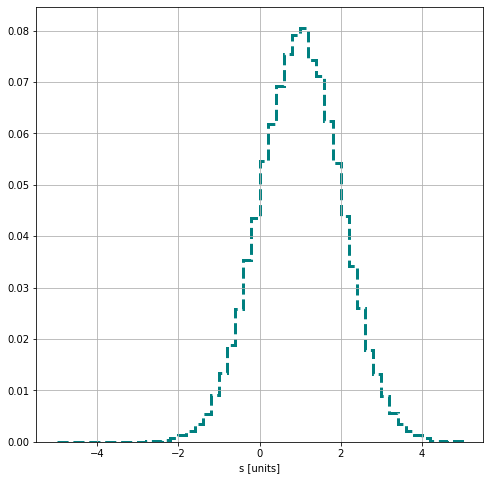

In [12]:
fig, ax = plt.subplots(figsize=(8,8))
sns.set_context('talk')
#h2.project("S").plot1d(ax=ax, ls="--", color="teal", lw=3)
hnorm = h2.project("S") / h2.project("S").sum()
hnorm.plot(ax=ax, ls="--", color="teal", lw=3)
plt.grid()
plt.show()

In [13]:
hnorm.sum()

1.0

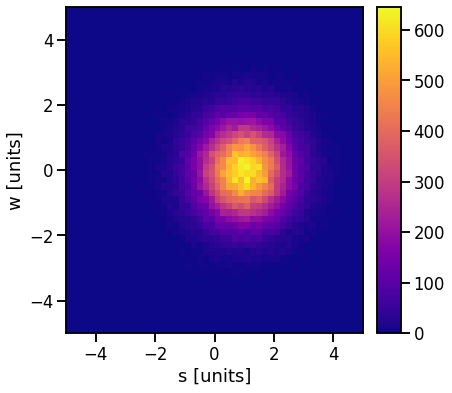

In [14]:
# plot2d
fig, ax = plt.subplots(figsize=(6, 6))

h2.plot2d(ax=ax, cmap="plasma")
plt.show()

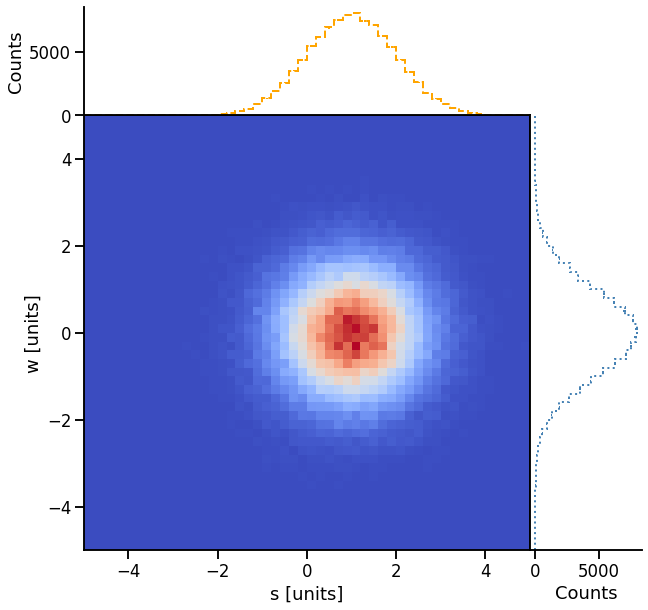

In [15]:
# plot2d_full
plt.figure(figsize=(10, 10))

h2.plot2d_full(
    main_cmap="coolwarm",
    top_ls="--",
    top_color="orange",
    top_lw=2,
    side_ls=":",
    side_lw=2,
    side_color="steelblue",
)

plt.show()

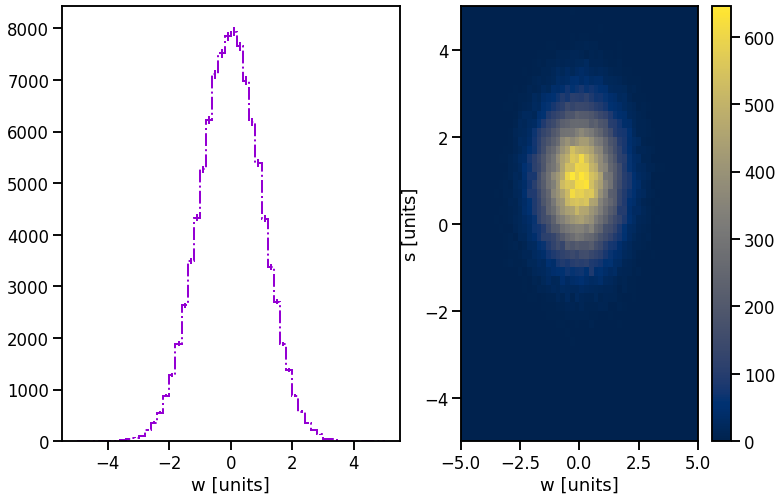

In [16]:
# auto-plot
fig, axs = plt.subplots(1, 2, figsize=(12, 8), gridspec_kw={"width_ratios": [5, 4]})


h2.project("W").plot(ax=axs[0], color="darkviolet", lw=2, ls="-.")
h2.project("W", "S").plot(ax=axs[1], cmap="cividis")

plt.show()

In [17]:
np.random.seed(0)

hist_1 = hist.Hist(
    hist.axis.Regular(
        50, -5, 5, name="X", label="x [units]", underflow=False, overflow=False
    )
).fill(np.random.normal(size=1000))

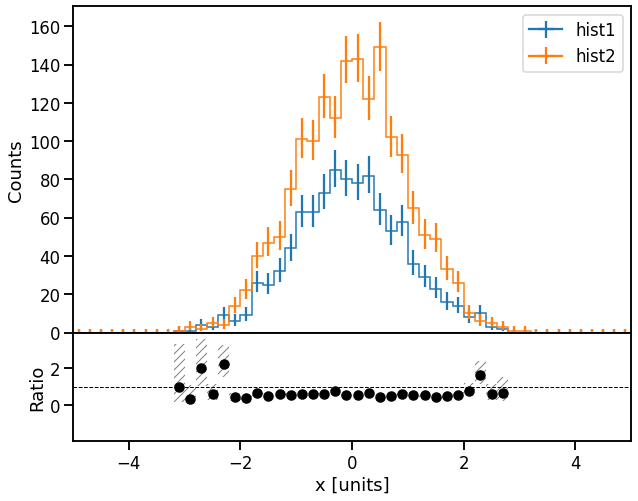

In [18]:
hist_2 = hist.Hist(
    hist.axis.Regular(
        50, -5, 5, name="X", label="x [units]", underflow=False, overflow=False
    )
).fill(np.random.normal(size=1700))

fig = plt.figure(figsize=(10, 8))
main_ax_artists, sublot_ax_arists = hist_1.plot_ratio(
    hist_2,
    rp_ylabel=r"Ratio",
    rp_num_label="hist1",
    rp_denom_label="hist2",
    rp_uncert_draw_type="bar",  # line or bar
)

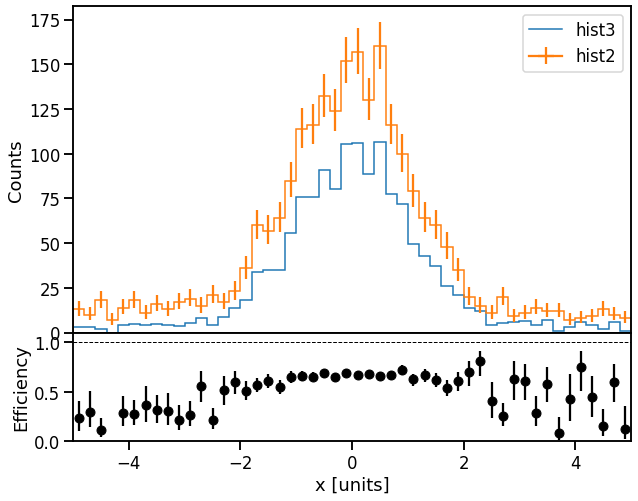

In [19]:
hist_3 = hist_2.copy() * 0.7
hist_2.fill(np.random.uniform(-5, 5, 600))
hist_3.fill(np.random.uniform(-5, 5, 200))

fig = plt.figure(figsize=(10, 8))
main_ax_artists, sublot_ax_arists = hist_3.plot_ratio(
    hist_2,
    rp_num_label="hist3",
    rp_denom_label="hist2",
    rp_uncert_draw_type="line",
    rp_uncertainty_type="efficiency",
)

In [20]:
hist_4 = hist_2.copy() * .7

In [21]:
type(hist_4)

hist.hist.Hist

In [22]:
hist_4[10] / .7

19.0

In [23]:
hist_2[10]

19.0

## Let's explore ROOT libraries

In [24]:
import ROOT as R

Welcome to JupyROOT 6.22/06


In [25]:
h1 = R.TH1F("h1","",200,-4,4)

In [26]:
type(h)

hist.hist.Hist

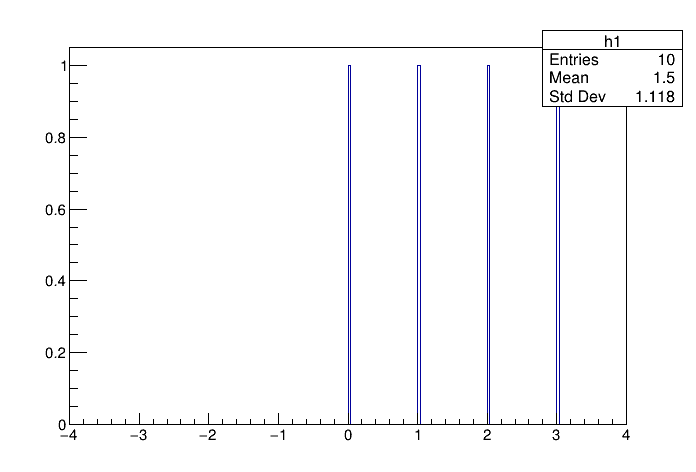

In [27]:
import numpy as np
for i in range(10):
    h1.Fill(i)
c1 = R.TCanvas()
h1.Draw()
c1.Draw()

In [28]:
h1.GetNbinsX()

200

In [29]:
fill = np.vectorize(R.TH1F.Fill)

In [30]:
def pdf(x, a=1 / np.sqrt(2 * np.pi), x0=0, sigma=1, offset=0):
    return a * np.exp(-((x - x0) ** 2) / (2 * sigma**2)) + offset

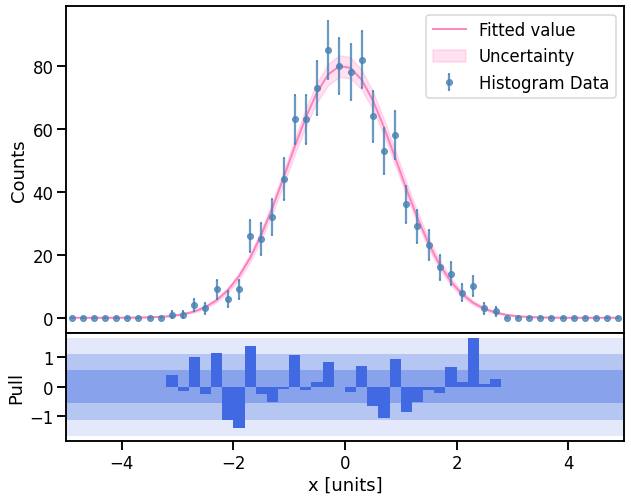

In [31]:
np.random.seed(0)

hist_1 = hist.Hist(
    hist.axis.Regular(
        50, -5, 5, name="X", label="x [units]", underflow=False, overflow=False
    )
).fill(np.random.normal(size=1000))

fig = plt.figure(figsize=(10, 8))
main_ax_artists, sublot_ax_arists = hist_1.plot_pull(
    "normal",
    eb_ecolor="steelblue",
    eb_mfc="steelblue",
    eb_mec="steelblue",
    eb_fmt="o",
    eb_ms=6,
    eb_capsize=1,
    eb_capthick=2,
    eb_alpha=0.8,
    fp_c="hotpink",
    fp_ls="-",
    fp_lw=2,
    fp_alpha=0.8,
    bar_fc="royalblue",
    pp_num=3,
    pp_fc="royalblue",
    pp_alpha=0.618,
    pp_ec=None,
    ub_alpha=0.2,
)